# Kandinsky 2.2 Inpainting

This notebook evaluates Kandinsky for replacing product backgrounds.
It uses the prepared images, masks and prompt from the SDXL experiment.
Run the code cells in order using a GPU runtime.

In [ ]:
%pip install -q diffusers transformers accelerate safetensors sentencepiece matplotlib "pandas==2.2.3" "pillow>=11,<13" "protobuf>=5.29.1,<7"

## Restore inputs

Upload "sdxl_batch_backup.zip" to restore the ten prepared product
images, masks and SDXL results.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sdxl_batch_backup.zip to sdxl_batch_backup.zip


In [ ]:
from pathlib import Path
import zipfile
import json
import torch
from PIL import Image

assert torch.cuda.is_available(), "Enable the GPU first."

project = Path("/content/image_comparison")
project.mkdir(parents=True, exist_ok=True)

# Find the uploaded backup
zip_files = [name for name in uploaded if name.lower().endswith(".zip")]
assert len(zip_files) == 1, "Upload one backup ZIP."

# Restore files safely
with zipfile.ZipFile(zip_files[0]) as archive:
    for name in archive.namelist():
        destination = (project / name).resolve()
        if not destination.is_relative_to(project.resolve()):
            raise ValueError("Unexpected file path in ZIP.")
    archive.extractall(project)

# Read the saved SDXL settings
config_files = sorted(
    (project / "results").glob("sdxl_config_*.json")
)
assert config_files, "SDXL configuration was not found."

config = json.loads(config_files[-1].read_text())

prompt = config["settings"]["prompt"]
negative_prompt = config["settings"]["negative_prompt"]
seeds = config["seeds"]

prepared_images = []

for name in config["products"]:
    image_path = project / "inputs" / f"{name}.png"
    mask_path = project / "masks" / f"{name}_mask.png"

    with Image.open(image_path) as image:
        saved_image = image.convert("RGB")

    with Image.open(mask_path) as mask:
        saved_mask = mask.convert("L")

    prepared_images.append({
        "name": name,
        "image": saved_image,
        "mask": saved_mask,
    })

print("GPU:", torch.cuda.get_device_name(0))
print("Restored products:", len(prepared_images))
print("Seeds:", seeds)
print("Prompt:", prompt)

GPU: Tesla T4
Restored products: 10
Seeds: [42, 123]
Prompt: A snack packet on a matte blue tabletop, solid dark blue background, blue studio backdrop, commercial product photography.


## Prepare prompt embeddings

The previous step converts the prompt into image embeddings for each seed.
These are saved and reused across the ten products. The prior is
unloaded before loading the decoder to reduce system RAM use.

In [ ]:
from diffusers import KandinskyV22PriorPipeline
import psutil

prior_id = "kandinsky-community/kandinsky-2-2-prior"

# Load only the prior
prior = KandinskyV22PriorPipeline.from_pretrained(
    prior_id,
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True,
)

prior.enable_model_cpu_offload()

print("Prior loaded.")
print("Available RAM:",
      round(psutil.virtual_memory().available / 1024**3, 2), "GB")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/501 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/776 [00:00<?, ?it/s]

Prior loaded.
Available RAM: 7.52 GB


In [ ]:
import time
import gc
from datetime import datetime, timezone

embedding_folder = project / "embeddings"
embedding_folder.mkdir(exist_ok=True)

prior_records = []

for seed in seeds:
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()

    # Convert the prompt to embeddings
    with torch.inference_mode():
        result = prior(
            prompt=prompt,
            negative_prompt=negative_prompt,
            num_inference_steps=25,
            guidance_scale=4.0,
            generator=torch.Generator("cpu").manual_seed(seed),
        )

    torch.cuda.synchronize()
    seconds = time.perf_counter() - start

    torch.save(
        {
            "image_embeds": result.image_embeds.detach().cpu(),
            "negative_image_embeds":
                result.negative_image_embeds.detach().cpu(),
        },
        embedding_folder / f"seed_{seed}.pt",
    )

    prior_records.append({
        "seed": seed,
        "seconds": round(seconds, 2),
        "peak_allocated_gpu_gb": round(
            torch.cuda.max_memory_allocated() / 1024**3, 3
        ),
    })

    del result
    print(f"Saved embeddings for seed {seed}")

# Record the prior settings
prior_log = {
    "model": prior_id,
    "prompt": prompt,
    "negative_prompt": negative_prompt,
    "steps": 25,
    "guidance_scale": 4.0,
    "precision": "float16",
    "scheduler": type(prior.scheduler).__name__,
    "scheduler_config": dict(prior.scheduler.config),
    "runs": prior_records,
    "embedding_reuse": "Each seed's embeddings reused across 10 products",
}

(project / "results" / "kandinsky_prior.json").write_text(
    json.dumps(prior_log, indent=2, default=str)
)

# Free memory before loading the decoder
prior.remove_all_hooks()
del prior
gc.collect()
torch.cuda.empty_cache()

print("\nPrior unloaded.")
print("Available RAM:",
      round(psutil.virtual_memory().available / 1024**3, 2), "GB")

  0%|          | 0/25 [00:00<?, ?it/s]

Saved embeddings for seed 42


  0%|          | 0/25 [00:00<?, ?it/s]

Saved embeddings for seed 123

Prior unloaded.
Available RAM: 8.17 GB


## Load the decoder

The inpainting decoder is loaded in float16 with CPU offloading.
It uses the saved embeddings, product image and mask to generate an output.

In [ ]:
from diffusers import KandinskyV22InpaintPipeline

model_b_id = "kandinsky-community/kandinsky-2-2-decoder-inpaint"

# Load decoder only
pipe_b = KandinskyV22InpaintPipeline.from_pretrained(
    model_b_id,
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True,
)

pipe_b.enable_model_cpu_offload()

print("Decoder loaded.")
print("Available RAM:",
      round(psutil.virtual_memory().available / 1024**3, 2), "GB")

model_index.json:   0%|          | 0.00/257 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/3 [00:00<?, ?it/s]

Decoder loaded.
Available RAM: 6.53 GB


## Pilot testing

One Doritos image is tested before running the full experiment.
This pilot is excluded from the final batch comparison.

  0%|          | 0/25 [00:00<?, ?it/s]

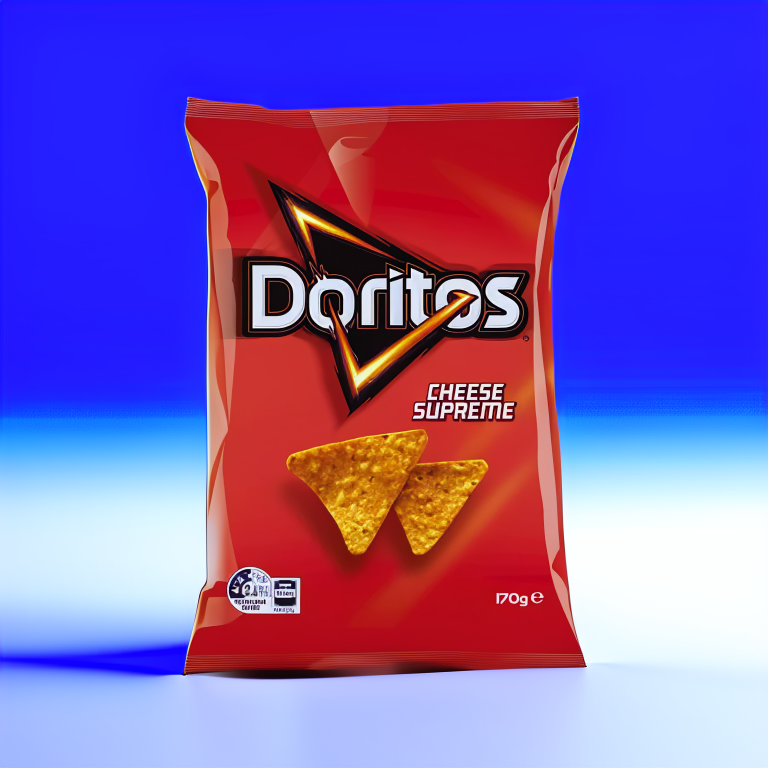

Decoder runtime: 15.35 seconds
Peak GPU allocation: 2.751 GB
Protected-region MAE: 17.5037


In [ ]:
import numpy as np
from IPython.display import display

item = next(x for x in prepared_images if x["name"] == "Doritos")
seed = 42

# Load saved prompt embeddings
embeddings = torch.load(
    project / "embeddings" / f"seed_{seed}.pt",
    map_location="cpu",
    weights_only=True,
)

decoder_settings = {
    "height": 768,
    "width": 768,
    "num_inference_steps": 25,
    "guidance_scale": 7.5,
}

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()

# Generate the background
with torch.inference_mode():
    output_b = pipe_b(
        image=item["image"],
        mask_image=item["mask"],
        image_embeds=embeddings["image_embeds"],
        negative_image_embeds=embeddings["negative_image_embeds"],
        generator=torch.Generator("cpu").manual_seed(seed),
        **decoder_settings,
    ).images[0]

torch.cuda.synchronize()
seconds = time.perf_counter() - start

run_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
filename = f"kandinsky_pilot_{run_id}.png"
output_b.save(project / "outputs" / filename)

# Measure raw output changes
before = np.asarray(item["image"], dtype=np.float32)
after = np.asarray(output_b, dtype=np.float32)
protected = np.asarray(item["mask"]) == 0

record = {
    "model": model_b_id,
    "product": item["name"],
    "seed": seed,
    "prompt": prompt,
    "negative_prompt": negative_prompt,
    "decoder_settings": decoder_settings,
    "scheduler": type(pipe_b.scheduler).__name__,
    "scheduler_config": dict(pipe_b.scheduler.config),
    "decoder_seconds": round(seconds, 2),
    "decoder_peak_allocated_gpu_gb": round(
        torch.cuda.max_memory_allocated() / 1024**3, 3
    ),
    "protected_mae": float(
        np.abs(after - before)[protected].mean()
    ),
    "output": filename,
    "stage": "pilot",
    "timing_note": "Prior generation measured separately; embeddings cached.",
}

(project / "results" / f"kandinsky_pilot_{run_id}.json").write_text(
    json.dumps(record, indent=2, default=str)
)

display(output_b)
print("Decoder runtime:", record["decoder_seconds"], "seconds")
print("Peak GPU allocation:",
      record["decoder_peak_allocated_gpu_gb"], "GB")
print("Protected-region MAE:", round(record["protected_mae"], 4))

## Final experiment

Ten products are tested with seeds 42 and 123, producing 20 outputs.
The decoder uses 25 steps and guidance 7.5. Decoder runtime, peak GPU
allocation and image-change metrics are recorded.
Prior processing is measured separately.

In [ ]:
import pandas as pd

batch_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
batch_folder = project / "outputs" / f"kandinsky_{batch_id}"
batch_folder.mkdir(parents=True, exist_ok=True)

rows_b = []

# Save batch settings
batch_config = {
    "model": model_b_id,
    "prior_model": prior_id,
    "prompt": prompt,
    "negative_prompt": negative_prompt,
    "decoder_settings": decoder_settings,
    "seeds": seeds,
    "products": [x["name"] for x in prepared_images],
    "scheduler": type(pipe_b.scheduler).__name__,
    "scheduler_config": dict(pipe_b.scheduler.config),
    "timing_note": "Decoder timed per output; prior embeddings cached.",
}

(project / "results" / f"kandinsky_config_{batch_id}.json").write_text(
    json.dumps(batch_config, indent=2, default=str)
)

for product in prepared_images:
    for run_seed in seeds:
        print(f"Running {product['name']} | seed {run_seed}")

        embeddings = torch.load(
            project / "embeddings" / f"seed_{run_seed}.pt",
            map_location="cpu",
            weights_only=True,
        )

        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        start = time.perf_counter()

        with torch.inference_mode():
            output = pipe_b(
                image=product["image"],
                mask_image=product["mask"],
                image_embeds=embeddings["image_embeds"],
                negative_image_embeds=embeddings["negative_image_embeds"],
                generator=torch.Generator("cpu").manual_seed(run_seed),
                **decoder_settings,
            ).images[0]

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        filename = f"{product['name']}_seed{run_seed}.png"
        output.save(batch_folder / filename)

        before = np.asarray(product["image"], dtype=np.float32)
        after = np.asarray(output, dtype=np.float32)
        protected = np.asarray(product["mask"]) == 0

        rows_b.append({
            "product": product["name"],
            "seed": run_seed,
            "decoder_seconds": round(elapsed, 2),
            "decoder_peak_allocated_gpu_gb": round(
                torch.cuda.max_memory_allocated() / 1024**3, 3
            ),
            "protected_mae": float(
                np.abs(after - before)[protected].mean()
            ),
            "background_mae": float(
                np.abs(after - before)[~protected].mean()
            ),
            "output": str((batch_folder / filename).relative_to(project)),
        })

        # Saving progress
        pd.DataFrame(rows_b).to_csv(
            project / "results" / f"kandinsky_metrics_{batch_id}.csv",
            index=False,
        )

print("Finished:", len(rows_b), "outputs")
display(pd.DataFrame(rows_b))

Running Coca_Cola | seed 42


  0%|          | 0/25 [00:00<?, ?it/s]

Running Coca_Cola | seed 123


  0%|          | 0/25 [00:00<?, ?it/s]

Running Coffee_cup | seed 42


  0%|          | 0/25 [00:00<?, ?it/s]

... (32 outputs left out)

Running Smiths_Orginal | seed 123


  0%|          | 0/25 [00:00<?, ?it/s]

Finished: 20 outputs


,product,seed,decoder_seconds,decoder_peak_allocated_gpu_gb,protected_mae,background_mae,output
0,Coca_Cola,42,12.05,2.751,29.107977,98.544266,outputs/kandinsky_20261101_023309/Coca_Cola_se...
1,Coca_Cola,123,11.89,2.751,35.086712,154.557968,outputs/kandinsky_20261101_023309/Coca_Cola_se...
2,Coffee_cup,42,12.04,2.751,14.055299,88.458115,outputs/kandinsky_20261101_023309/Coffee_cup_s...
3,Coffee_cup,123,12.31,2.751,20.907188,149.046997,outputs/kandinsky_20261101_023309/Coffee_cup_s...
4,Doritos,42,12.21,2.751,17.517042,98.003418,outputs/kandinsky_20261101_023309/Doritos_seed...
5,Doritos,123,12.28,2.751,22.019482,149.343399,outputs/kandinsky_20261101_023309/Doritos_seed...
6,KitKat,42,12.49,2.751,25.007338,102.868202,outputs/kandinsky_20261101_023309/KitKat_seed4...
7,KitKat,123,12.80,2.751,31.537218,146.037796,outputs/kandinsky_20261101_023309/KitKat_seed1...
8,Mount_Franklin,42,13.27,2.751,30.114986,100.251694,outputs/kandinsky_20261101_023309/Mount_Frankl...
9,Mount_Franklin,123,13.52,2.751,43.933857,188.413162,outputs/kandinsky_20261101_023309/Mount_Frankl...


## Save comparison and download

Results are matched by product and seed. The timing summary shows
SDXL inference and Kandinsky decoder time and prior time is stored separately.

Both models inputs, masks, outputs and logs are downloaded as
"pair1_both_models_backup.zip".

In [ ]:
import pandas as pd
import shutil
from google.colab import files

# Read both result tables
sdxl_file = sorted(
    (project / "results").glob("sdxl_metrics_*.csv")
)[-1]

kandinsky_file = (
    project / "results" / f"kandinsky_metrics_{batch_id}.csv"
)

sdxl = pd.read_csv(sdxl_file)
kandinsky = pd.read_csv(kandinsky_file)

# Match product and seed
comparison = sdxl.merge(
    kandinsky,
    on=["product", "seed"],
    suffixes=("_sdxl", "_kandinsky"),
    validate="one_to_one",
)

assert len(comparison) == 20, "Expected 20 matched test cases."

comparison.to_csv(
    project / "results" / "paired_comparison.csv",
    index=False,
)

summary = pd.DataFrame([
    {
        "model": "SDXL",
        "outputs": len(sdxl),
        "mean_protected_mae": sdxl["protected_mae"].mean(),
        "mean_seconds": sdxl["seconds"].mean(),
        "timing_scope": "SDXL inference",
    },
    {
        "model": "Kandinsky",
        "outputs": len(kandinsky),
        "mean_protected_mae": kandinsky["protected_mae"].mean(),
        "mean_seconds": kandinsky["decoder_seconds"].mean(),
        "timing_scope": "Decoder only; cached prior embeddings",
    },
])

summary.to_csv(
    project / "results" / "model_summary.csv",
    index=False,
)

display(summary.round(3))

# Back up both models' results
backup = shutil.make_archive(
    "/content/pair1_both_models_backup",
    "zip",
    root_dir=str(project),
)

files.download(backup)

,model,outputs,mean_protected_mae,mean_seconds,timing_scope
0,SDXL,20,27.752,18.856,SDXL inference
1,Kandinsky,20,28.933,12.642,Decoder only; cached prior embeddings


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>